<a href="https://colab.research.google.com/github/MuskanZehra5/QML_Project_Diabetic_Retinopathy/blob/main/Part3_Quantum_Head_and_Hardware.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# clone the project github repository

!git clone https://github.com/MuskanZehra5/QML_Project_Diabetic_Retinopathy.git

%cd QML_Project_Diabetic_Retinopathy

!git status

Cloning into 'QML_Project_Diabetic_Retinopathy'...
remote: Enumerating objects: 12, done.
remote: Counting objects: 100% (12/12), done.
remote: Compressing objects: 100% (10/10), done.
remote: Total 12 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (12/12), 1.79 MiB | 4.87 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/QML_Project_Diabetic_Retinopathy
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean


In [2]:
# mount google drive for feature files

from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# check the saved 8-feature dataset

import os

feature_path = "/content/drive/MyDrive/MMRDR-CFP/features/dr_features.npz"

print("feature file exists:", os.path.exists(feature_path))
print("feature path:", feature_path)

feature file exists: False
feature path: /content/drive/MyDrive/MMRDR-CFP/features/dr_features.npz


In [8]:
# list visible folders in my drive

import os

print(os.listdir("/content/drive/MyDrive"))

['Colab Notebooks', 'International Examinations.pdf', 'pic', 'lec1.gdoc', 'Untitled document (9).gdoc', 'Untitled document (8).gdoc', 'Untitled document (7).gdoc', 'Untitled document (6).gdoc', 'Untitled document (5).gdoc', 'Untitled document (4).gdoc', 'Copy of Untitled document.gdoc', 'Untitled document (3).gdoc', 'Untitled document (2).gdoc', 'vsy-cjbf-qai - Oct 23, 2021.pdf', 'IMG_6238 (1).JPG', 'IMG_6192.JPG', 'IMG_6193.JPG', 'IMG_6238.JPG', 'Addictions - Youth Wing - Final (1).pptx', 'Addictions - Youth Wing - Final.pptx', 'Copy of Year 6 English Comprehension- River Rescue.gdoc', 'Untitled document (1).gdoc', 'Classroom', 'misc.pdf', 'misc (1).gdoc', 'misc.gdoc', 'WhatsApp Image 2023-07-24 at 6.24.11 PM.jpeg', 'WhatsApp Image 2023-07-24 at 6.24.13 PM.jpeg', 'WhatsApp Image 2023-07-24 at 6.24.14 PM.jpeg', 'to-do-list.gsheet', 'Untitled document.gdoc', 'THE SEXUAL REVOLUTION PRESENTATION.pptx', 'Copy of Y7&8M - Prime Numbers 2.gdoc', 'Gohar Nayyab - Standard Job Application Form .

In [9]:
# check shared feature folder

import os

feature_dir = "/content/drive/MyDrive/features"

print(os.listdir(feature_dir))

['dr_features.npz']


In [10]:
# load the saved 8-feature dataset

import numpy as np

feature_path = "/content/drive/MyDrive/features/dr_features.npz"

data = np.load(feature_path)

X_train = data["X_train"]
y_train = data["y_train"]

X_val = data["X_val"]
y_val = data["y_val"]

X_test = data["X_test"]
y_test = data["y_test"]

print("train:", X_train.shape, y_train.shape)
print("validation:", X_val.shape, y_val.shape)
print("test:", X_test.shape, y_test.shape)

print("train labels:", np.unique(y_train, return_counts=True))

train: (1849, 8) (1849,)
validation: (463, 8) (463,)
test: (581, 8) (581,)
train labels: (array([0, 1, 2, 3, 4]), array([1133,  218,  302,   94,  102]))


In [11]:
# convert dr grades to binary referable labels

y_train_bin = (y_train >= 2).astype(int)
y_val_bin = (y_val >= 2).astype(int)
y_test_bin = (y_test >= 2).astype(int)

print("train binary:", np.unique(y_train_bin, return_counts=True))
print("validation binary:", np.unique(y_val_bin, return_counts=True))
print("test binary:", np.unique(y_test_bin, return_counts=True))

print("train prevalence:", y_train_bin.mean())
print("validation prevalence:", y_val_bin.mean())
print("test prevalence:", y_test_bin.mean())

train binary: (array([0, 1]), array([1351,  498]))
validation binary: (array([0, 1]), array([338, 125]))
test binary: (array([0, 1]), array([415, 166]))
train prevalence: 0.2693347755543537
validation prevalence: 0.26997840172786175
test prevalence: 0.2857142857142857


In [12]:
# scale 8 features for quantum angle encoding

import numpy as np
from sklearn.preprocessing import MinMaxScaler

quantum_scaler = MinMaxScaler(feature_range=(0, np.pi))

X_train_q = quantum_scaler.fit_transform(X_train)
X_val_q = quantum_scaler.transform(X_val)
X_test_q = quantum_scaler.transform(X_test)

print("train range:", X_train_q.min(), X_train_q.max())
print("validation range:", X_val_q.min(), X_val_q.max())
print("test range:", X_test_q.min(), X_test_q.max())

print("train shape:", X_train_q.shape)

train range: 0.0 3.141593
validation range: 0.040389657 3.323647
test range: -0.15686285 3.739607
train shape: (1849, 8)


In [13]:
# clip quantum features to valid angle range

X_train_q = np.clip(X_train_q, 0, np.pi)
X_val_q = np.clip(X_val_q, 0, np.pi)
X_test_q = np.clip(X_test_q, 0, np.pi)

print("train range:", X_train_q.min(), X_train_q.max())
print("validation range:", X_val_q.min(), X_val_q.max())
print("test range:", X_test_q.min(), X_test_q.max())

train range: 0.0 3.1415927
validation range: 0.040389657 3.1415927
test range: 0.0 3.1415927


In [14]:
# install qiskit packages for the quantum model

!pip -q install qiskit qiskit-aer qiskit-machine-learning

In [15]:
# check qiskit installation

import qiskit
import qiskit_aer

print("qiskit version:", qiskit.__version__)
print("qiskit aer loaded successfully")

qiskit version: 2.6.2
qiskit aer loaded successfully


In [21]:
# install circuit drawing packages

!pip install -q pylatexenc matplotlib

In [1]:
# rebuild the 8-qubit quantum circuit

import numpy as np

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

n_qubits = 8
n_layers = 2

x_params = ParameterVector("x", n_qubits)
theta = ParameterVector("theta", n_layers * n_qubits * 2)

qc = QuantumCircuit(n_qubits)

# encode input features
for q in range(n_qubits):
    qc.ry(x_params[q], q)

param_index = 0

# add trainable layers
for layer in range(n_layers):

    for q in range(n_qubits):
        qc.ry(theta[param_index], q)
        param_index += 1

        qc.rz(theta[param_index], q)
        param_index += 1

    # linear entanglement
    for q in range(n_qubits - 1):
        qc.cx(q, q + 1)

print("qubits:", qc.num_qubits)
print("input parameters:", len(x_params))
print("trainable parameters:", len(theta))

qubits: 8
input parameters: 8
trainable parameters: 32


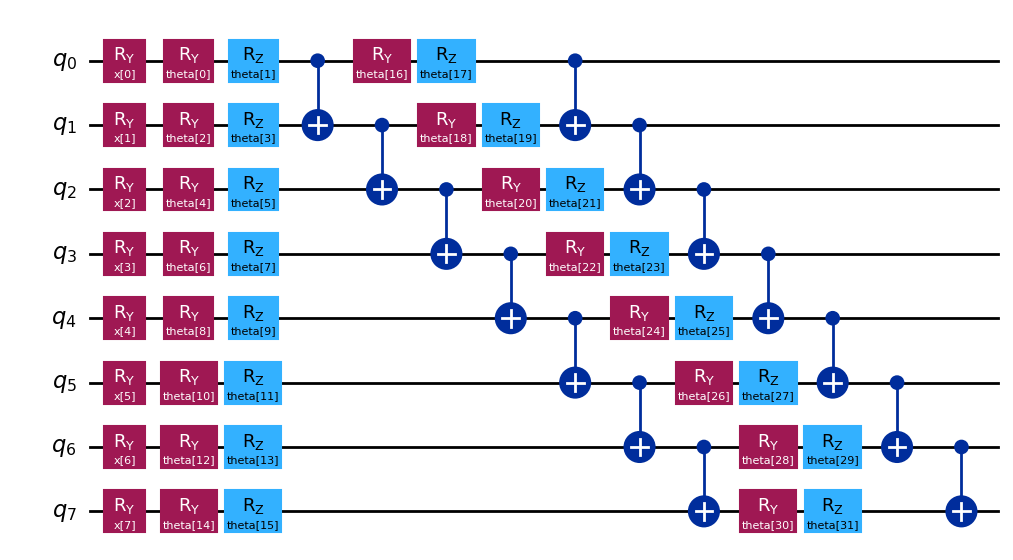

In [2]:
# draw the circuit for the report

from qiskit.visualization import circuit_drawer

fig = circuit_drawer(
    qc,
    output="mpl",
    fold=100
)

fig

In [3]:
# save the circuit figure

fig.savefig(
    "/content/QML_Project_Diabetic_Retinopathy/quantum_circuit.png",
    dpi=300,
    bbox_inches="tight"
)

In [5]:
# reload and scale the 8-feature dataset

import numpy as np
from sklearn.preprocessing import MinMaxScaler

feature_path = "/content/drive/MyDrive/features/dr_features.npz"
data = np.load(feature_path)

X_train = data["X_train"]
y_train = data["y_train"]

X_val = data["X_val"]
y_val = data["y_val"]

X_test = data["X_test"]
y_test = data["y_test"]

# binary referable dr labels
y_train_bin = (y_train >= 2).astype(int)
y_val_bin = (y_val >= 2).astype(int)
y_test_bin = (y_test >= 2).astype(int)

# scale features for quantum encoding
quantum_scaler = MinMaxScaler(feature_range=(0, np.pi))

X_train_q = quantum_scaler.fit_transform(X_train)
X_val_q = quantum_scaler.transform(X_val)
X_test_q = quantum_scaler.transform(X_test)

# clip to valid angle range
X_train_q = np.clip(X_train_q, 0, np.pi)
X_val_q = np.clip(X_val_q, 0, np.pi)
X_test_q = np.clip(X_test_q, 0, np.pi)

print("train:", X_train_q.shape)
print("validation:", X_val_q.shape)
print("test:", X_test_q.shape)

train: (1849, 8)
validation: (463, 8)
test: (581, 8)


In [6]:
# create the quantum neural network

import numpy as np

from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp
from qiskit_machine_learning.neural_networks import EstimatorQNN

estimator = StatevectorEstimator()

# measure z on qubit 0
observable = SparsePauliOp.from_list([
    ("IIIIIIIZ", 1.0)
])

qnn = EstimatorQNN(
    circuit=qc,
    observables=observable,
    input_params=list(x_params),
    weight_params=list(theta),
    estimator=estimator
)

initial_weights = np.random.default_rng(42).normal(
    0,
    0.1,
    len(theta)
)

test_output = qnn.forward(
    X_train_q[:3],
    initial_weights
)

print("qnn inputs:", qnn.num_inputs)
print("qnn weights:", qnn.num_weights)
print("test output shape:", test_output.shape)
print("test outputs:")
print(test_output)

qnn inputs: 8
qnn weights: 32
test output shape: (3, 1)
test outputs:
[[ 0.84290284]
 [ 0.85843581]
 [-0.84704277]]


In [7]:
# check qnn gradients for trainability

sample_x = X_train_q[:10]

_, weight_grad = qnn.backward(
    sample_x,
    initial_weights
)

print("gradient shape:", weight_grad.shape)
print("mean absolute gradient:", np.mean(np.abs(weight_grad)))
print("gradient variance:", np.var(weight_grad))
print("minimum gradient:", weight_grad.min())
print("maximum gradient:", weight_grad.max())

gradient shape: (10, 1, 32)
mean absolute gradient: 0.03903138492123079
gradient variance: 0.02652737948941105
minimum gradient: -0.9983035770403703
maximum gradient: 0.01751432053434243


The important numbers are:
- mean absolute gradient = 0.039
- gradient variance = 0.0265
- gradients are clearly non-zero
So the circuit is not stuck in a barren plateau at initialization. The very asymmetric min/max is okay at this stage; what matters is that the gradients are not vanishing.

### Prepare a smaller training subset

Training a variational quantum circuit is much more computationally expensive than training a classical model. Therefore, we first use a smaller stratified subset of the training data to confirm that the quantum model can learn properly.

Stratified sampling keeps the same proportion of referable and non-referable DR cases as the full training set. Once the model is shown to train correctly, we can use the same setup for the full experiments.

In [8]:
# prepare a balanced training subset

from sklearn.model_selection import train_test_split

X_q_small, _, y_q_small, _ = train_test_split(
    X_train_q,
    y_train_bin,
    train_size=400,
    random_state=42,
    stratify=y_train_bin
)

print("training subset:", X_q_small.shape)
print("class counts:", np.bincount(y_q_small))

training subset: (400, 8)
class counts: [292 108]


### Training subset check

The 400-sample subset contains 292 non-referable and 108 referable DR cases. This keeps approximately the same class distribution as the full training set, so the initial quantum training test remains representative while reducing simulation cost.

### Define the quantum training objective

The quantum circuit returns an expectation value between -1 and +1. We convert this value into a probability between 0 and 1 and train the circuit for binary classification of referable DR.

Binary cross-entropy is used as the loss function. The circuit parameters are updated using a classical optimizer while the quantum circuit provides the model output.

In [9]:
# define quantum loss function

from scipy.optimize import minimize
from sklearn.metrics import log_loss

def quantum_probabilities(weights, X):
    outputs = qnn.forward(X, weights).reshape(-1)

    probabilities = (1 - outputs) / 2
    probabilities = np.clip(probabilities, 1e-6, 1 - 1e-6)

    return probabilities


def objective(weights):
    probabilities = quantum_probabilities(weights, X_q_small)

    loss = log_loss(
        y_q_small,
        probabilities
    )

    return loss


initial_loss = objective(initial_weights)

print("initial loss:", initial_loss)

initial loss: 0.339453979443186


In [10]:
# optimize the quantum circuit parameters

loss_history = []

def callback(weights):
    current_loss = objective(weights)
    loss_history.append(current_loss)

result = minimize(
    objective,
    initial_weights,
    method="COBYLA",
    callback=callback,
    options={
        "maxiter": 50,
        "disp": True
    }
)

trained_weights = result.x

print("initial loss:", initial_loss)
print("final loss:", result.fun)
print("iterations:", result.nfev)
print("success:", result.success)

Return from COBYLA because the objective function has been evaluated MAXFUN times.
Number of function values = 50   Least value of F = 0.3216935315059802
The corresponding X is:
[-0.18724108  0.89429207  0.08060208  1.09144038  0.77116649  0.75782193
  0.01169427  0.96863804 -0.00184386 -0.08542598  0.08532347  1.08009578
  0.00285003  0.11041323  0.0436688  -0.0893088   0.00224349 -0.09751883
  0.08479275 -0.00826671 -0.01878074 -0.07183941  0.12087195 -0.01782117
 -0.04672443 -0.03846494  0.04937924  0.03582918  0.03924166  0.03894759
  0.21154561 -0.04504627]

initial loss: 0.339453979443186
final loss: 0.3216935315059802
iterations: 50
success: False


In [11]:
# evaluate trained quantum model on validation data

from sklearn.metrics import roc_auc_score

val_probs = quantum_probabilities(
    trained_weights,
    X_val_q
)

val_auc = roc_auc_score(
    y_val_bin,
    val_probs
)

print("validation auc:", val_auc)

validation auc: 0.9109349112426035


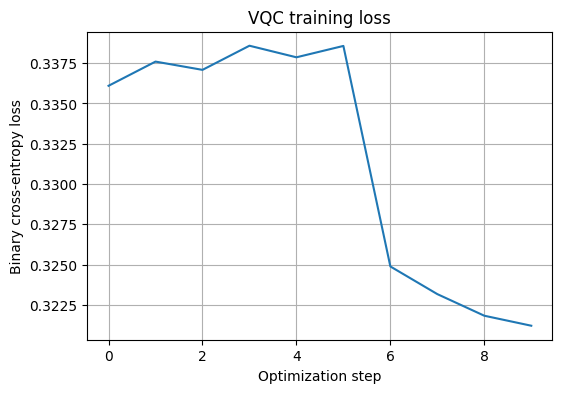

In [12]:
# plot quantum training loss

import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(loss_history)
plt.xlabel("Optimization step")
plt.ylabel("Binary cross-entropy loss")
plt.title("VQC training loss")
plt.grid(True)
plt.show()

### Training loss interpretation

The VQC loss decreases from approximately 0.339 to 0.322 during optimization. Although there are small fluctuations in the first few steps, the overall downward trend shows that the quantum model is learning and the circuit is trainable.

The trained model also achieved a validation AUC of 0.911, indicating strong discrimination between referable and non-referable DR cases.

### Finite-shot evaluation

The ideal statevector result assumes exact expectation values. Real quantum hardware estimates outputs from repeated measurements, so we test how the trained VQC behaves when only a finite number of shots are available.

In [13]:
# prepare measured circuit for shot-based evaluation

from qiskit_aer import AerSimulator
from qiskit import transpile

shot_simulator = AerSimulator()

measured_qc = qc.copy()
measured_qc.measure_all()

print("measured circuit ready")
print("qubits:", measured_qc.num_qubits)

measured circuit ready
qubits: 8


### Shot-noise experiment

Real quantum devices estimate measurement outcomes using a finite number of shots. Fewer shots introduce more statistical noise, while larger shot counts should produce results closer to the ideal statevector model.

We therefore evaluate the trained VQC using 256, 1024, 4096 and 8192 shots and compare the resulting validation AUC.

In [14]:
# evaluate trained vqc with finite shots

import numpy as np
from sklearn.metrics import roc_auc_score
from qiskit import transpile

def shot_probabilities(X, weights, shots):
    probs = []

    for x in X:
        bound = measured_qc.assign_parameters(
            {
                **{x_params[i]: float(x[i]) for i in range(8)},
                **{theta[i]: float(weights[i]) for i in range(32)}
            }
        )

        tqc = transpile(bound, shot_simulator)

        result = shot_simulator.run(
            tqc,
            shots=shots
        ).result()

        counts = result.get_counts()

        total = sum(counts.values())

        z_expectation = 0.0

        for bitstring, count in counts.items():
            q0_bit = int(bitstring[-1])

            if q0_bit == 0:
                z_expectation += count
            else:
                z_expectation -= count

        z_expectation /= total

        prob = (1 - z_expectation) / 2
        probs.append(prob)

    return np.array(probs)


shot_results = []

for shots in [256, 1024, 4096, 8192]:

    probs = shot_probabilities(
        X_val_q,
        trained_weights,
        shots
    )

    auc = roc_auc_score(
        y_val_bin,
        probs
    )

    shot_results.append((shots, auc))

    print("shots:", shots, "auc:", auc)

shots: 256 auc: 0.9075147928994083
shots: 1024 auc: 0.9081065088757396
shots: 4096 auc: 0.9094201183431951
shots: 8192 auc: 0.9103431952662722


### Shot-noise results

The VQC remained stable across different shot counts. Performance improved gradually as the number of shots increased, approaching the ideal statevector AUC of 0.911.

Even at 256 shots, the validation AUC remained above 0.907, showing that the trained quantum model is relatively robust to finite-shot measurement noise.

### Noise-model experiment

Finite shots only model measurement uncertainty. Real quantum hardware also introduces gate and readout errors. To study this effect, we evaluate the trained VQC using a noisy simulator and compare its AUC with the ideal and finite-shot results.

In [15]:
# create a simple realistic noise model

from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError
from qiskit_aer import AerSimulator

noise_model = NoiseModel()

# single-qubit gate error
error_1q = depolarizing_error(0.001, 1)

# two-qubit gate error
error_2q = depolarizing_error(0.01, 2)

# readout error
readout_error = ReadoutError([
    [0.98, 0.02],
    [0.03, 0.97]
])

noise_model.add_all_qubit_quantum_error(
    error_1q,
    ["ry", "rz"]
)

noise_model.add_all_qubit_quantum_error(
    error_2q,
    ["cx"]
)

noise_model.add_all_qubit_readout_error(
    readout_error
)

noisy_simulator = AerSimulator(
    noise_model=noise_model
)

print("noise model ready")

noise model ready


In [16]:
# evaluate the trained vqc with the noise model

def noisy_probabilities(X, weights, shots=4096):
    probs = []

    for x in X:
        bound = measured_qc.assign_parameters(
            {
                **{x_params[i]: float(x[i]) for i in range(8)},
                **{theta[i]: float(weights[i]) for i in range(32)}
            }
        )

        tqc = transpile(bound, noisy_simulator)

        result = noisy_simulator.run(
            tqc,
            shots=shots
        ).result()

        counts = result.get_counts()
        total = sum(counts.values())

        z_expectation = 0.0

        for bitstring, count in counts.items():
            q0_bit = int(bitstring[-1])

            if q0_bit == 0:
                z_expectation += count
            else:
                z_expectation -= count

        z_expectation /= total

        prob = (1 - z_expectation) / 2
        probs.append(prob)

    return np.array(probs)


noisy_probs = noisy_probabilities(
    X_val_q,
    trained_weights,
    shots=4096
)

noisy_auc = roc_auc_score(
    y_val_bin,
    noisy_probs
)

print("noisy validation auc:", noisy_auc)

noisy validation auc: 0.9099763313609466


### Noise-model result

The noisy simulator achieved a validation AUC of 0.910, which is almost identical to the ideal statevector result of 0.911. This suggests that the trained VQC is relatively robust to the moderate gate and readout noise used in this experiment.

In [17]:
# summarize ideal shot and noise results

import pandas as pd

comparison_df = pd.DataFrame({
    "Setting": [
        "Ideal statevector",
        "256 shots",
        "1024 shots",
        "4096 shots",
        "8192 shots",
        "Noisy simulator"
    ],
    "Validation AUC": [
        val_auc,
        shot_results[0][1],
        shot_results[1][1],
        shot_results[2][1],
        shot_results[3][1],
        noisy_auc
    ]
})

print(comparison_df.to_string(index=False))

          Setting  Validation AUC
Ideal statevector        0.910935
        256 shots        0.907515
       1024 shots        0.908107
       4096 shots        0.909420
       8192 shots        0.910343
  Noisy simulator        0.909976


In [18]:
# list project folders in my drive

import os

for folder in ["features", "results", "splits"]:
    path = f"/content/drive/MyDrive/{folder}"
    print(f"\n{folder.upper()}:")

    if os.path.exists(path):
        print(os.listdir(path))
    else:
        print("not found")


FEATURES:
['dr_features.npz']

RESULTS:
not found

SPLITS:
not found


In [19]:
# save trained quantum results and weights

import os
import numpy as np

save_dir = "/content/QML_Project_Diabetic_Retinopathy/results"
os.makedirs(save_dir, exist_ok=True)

np.save(
    os.path.join(save_dir, "trained_vqc_weights.npy"),
    trained_weights
)

comparison_df.to_csv(
    os.path.join(save_dir, "quantum_noise_results.csv"),
    index=False
)

print("results saved")

results saved


In [20]:
# search drive for local feature files

import os

keywords = ["local", "feature", "dfpd"]

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        name = file.lower()

        if any(key in name for key in keywords):
            if name.endswith((".npz", ".npy", ".csv")):
                print(os.path.join(root, file))

/content/drive/MyDrive/QML_Project/local_resnet18_features.csv


In [21]:
# inspect local feature file

import pandas as pd

local_path = "/content/drive/MyDrive/QML_Project/local_resnet18_features.csv"

local_df = pd.read_csv(local_path)

print("shape:", local_df.shape)
print("columns:", local_df.columns[:10].tolist())
print(local_df.head())

shape: (253, 513)
columns: ['image_id', '0', '1', '2', '3', '4', '5', '6', '7', '8']
    image_id         0         1         2         3         4         5  \
0  DFPD_0001  1.812013  0.525138  0.157909  0.674978  0.157771  1.832206   
1  DFPD_0002  1.944981  0.191333  0.136081  1.314859  0.000000  0.886168   
2  DFPD_0003  0.748822  0.142305  0.478735  1.062362  1.331536  0.590377   
3  DFPD_0004  2.058066  1.292499  0.516906  0.766557  0.227847  0.894846   
4  DFPD_0005  1.898600  1.270241  0.813657  0.955033  0.085784  0.478877   

          6         7         8  ...       502       503       504       505  \
0  0.256419  0.410875  1.486751  ...  0.043643  2.470236  1.544229  0.252688   
1  0.002750  0.216617  1.497585  ...  0.010186  3.219304  2.187679  0.564532   
2  0.235090  0.193584  2.758917  ...  0.081211  0.000000  1.917838  1.023450   
3  0.068078  0.239617  1.614373  ...  0.000000  2.811484  0.526827  0.136338   
4  0.060569  0.500095  1.166930  ...  0.000000  2.991263  

In [23]:
# search my drive for the trained checkpoint

import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file == "best_resnet18.pth":
            print(os.path.join(root, file))

/content/drive/MyDrive/best_resnet18.pth


In [24]:
# rebuild the trained resnet18 feature model

import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class DRModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.backbone = resnet18(
            weights=ResNet18_Weights.DEFAULT
        )

        self.backbone.fc = nn.Identity()

        self.bottleneck = nn.Linear(512, 8)

        self.classifier = nn.Linear(8, 5)

    def extract_features(self, x):
        x = self.backbone(x)
        x = self.bottleneck(x)
        return x

    def forward(self, x):
        features = self.extract_features(x)
        return self.classifier(features)


model = DRModel().to(device)

checkpoint_path = "/content/drive/MyDrive/best_resnet18.pth"

model.load_state_dict(
    torch.load(
        checkpoint_path,
        map_location=device
    )
)

model.eval()

print("checkpoint loaded successfully")
print("device:", device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 137MB/s]


checkpoint loaded successfully
device: cuda


In [25]:
# locate local fundus image files

import os

image_exts = (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")

matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    image_files = [
        f for f in files
        if f.lower().endswith(image_exts)
    ]

    if len(image_files) >= 50:
        matches.append((root, len(image_files)))

for path, count in matches:
    print(count, "images ->", path)

5349 images -> /content/drive/MyDrive/new_x_
5367 images -> /content/drive/MyDrive/new_y_
404 images -> /content/drive/MyDrive/QML_Project/APTOS2019/extracted/test_images


In [26]:
# check local hospital image folder

import os

local_image_dir = "/content/drive/MyDrive/D:/DATA"

print("folder exists:", os.path.exists(local_image_dir))

image_exts = (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")

local_images = [
    f for f in os.listdir(local_image_dir)
    if f.lower().endswith(image_exts)
]

print("image count:", len(local_images))
print("first files:", local_images[:10])

folder exists: True
image count: 255
first files: ['bab50949-2d05-4c6b-8ae0-740bef59ebbc.png', 'fb6ff7b1-848e-45bb-bd17-a665d5523df2.png', '{53B7030B-FB0C-4520-B2CC-C5FCCBA1965C}.png', 'c15072bd-32b6-43a5-95a6-ed7672cfd7d6.png', '0d334103-ea06-44a2-8e61-ec027b4c3896.png', '296e4d88-4bb3-4439-9efb-4de9465bce6b.png', '005dbb3e-bddc-460d-89bf-9d6bbc0ba969.png', 'ab025b88-da20-40aa-a305-b7990e6cc795.png', '95b92fc1-f65a-429d-9c64-b285d2d2a395.png', 'cc86a3fd-be84-4e59-b7a4-297743ba1d85.png']


In [27]:
# extract 8-dimensional local features

import os
import torch
import pandas as pd
import numpy as np

from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

local_image_dir = "/content/drive/MyDrive/D:/DATA"

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class LocalRetinalDataset(Dataset):

    def __init__(self, image_dir, transform=None):
        self.image_dir = image_dir
        self.transform = transform

        self.files = sorted([
            f for f in os.listdir(image_dir)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")
            )
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        filename = self.files[idx]

        image_path = os.path.join(
            self.image_dir,
            filename
        )

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, filename


local_dataset = LocalRetinalDataset(
    local_image_dir,
    eval_transform
)

local_loader = DataLoader(
    local_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

all_features = []
all_filenames = []

model.eval()

with torch.no_grad():

    for images, filenames in local_loader:

        images = images.to(device)

        features = model.extract_features(images)

        all_features.append(
            features.cpu().numpy()
        )

        all_filenames.extend(filenames)


X_local_8 = np.concatenate(
    all_features,
    axis=0
)

print("local features shape:", X_local_8.shape)
print("number of filenames:", len(all_filenames))

local features shape: (255, 8)
number of filenames: 255


In [28]:
# remove duplicate local images using saved clean ids

clean_ids_path = "/content/drive/MyDrive/QML_Project/master_images.csv"

clean_ids_df = pd.read_csv(clean_ids_path)

print("clean rows:", len(clean_ids_df))
print(clean_ids_df[["image_id", "filename"]].head())

clean rows: 253
    image_id                                    filename
0  DFPD_0001    bab50949-2d05-4c6b-8ae0-740bef59ebbc.png
1  DFPD_0002    fb6ff7b1-848e-45bb-bd17-a665d5523df2.png
2  DFPD_0003  {53B7030B-FB0C-4520-B2CC-C5FCCBA1965C}.png
3  DFPD_0004    c15072bd-32b6-43a5-95a6-ed7672cfd7d6.png
4  DFPD_0005    0d334103-ea06-44a2-8e61-ec027b4c3896.png


In [29]:
# merge 8 features with cleaned local image ids

feature_df = pd.DataFrame(
    X_local_8,
    columns=[f"feature_{i+1}" for i in range(8)]
)

feature_df.insert(0, "filename", all_filenames)

local_8_clean = clean_ids_df[
    ["image_id", "filename"]
].merge(
    feature_df,
    on="filename",
    how="inner"
)

print("clean local feature shape:", local_8_clean.shape)
print(local_8_clean.head())

clean local feature shape: (253, 10)
    image_id                                    filename  feature_1  \
0  DFPD_0001    bab50949-2d05-4c6b-8ae0-740bef59ebbc.png  -1.143584   
1  DFPD_0002    fb6ff7b1-848e-45bb-bd17-a665d5523df2.png  -4.399729   
2  DFPD_0003  {53B7030B-FB0C-4520-B2CC-C5FCCBA1965C}.png  -0.230689   
3  DFPD_0004    c15072bd-32b6-43a5-95a6-ed7672cfd7d6.png  -3.895200   
4  DFPD_0005    0d334103-ea06-44a2-8e61-ec027b4c3896.png  -3.907179   

   feature_2  feature_3  feature_4  feature_5  feature_6  feature_7  feature_8  
0  -1.070313  -1.164572  -1.801556  -1.688309   1.852012   1.959394  -0.984547  
1  -3.005526   0.610265  -4.790978  -2.071913   3.080692   1.933629  -3.415226  
2  -1.892590   2.746780  -0.211900   2.963840  -2.575263  -1.867721   0.024561  
3  -2.946714   0.980112  -4.592420  -2.738458   3.800953   2.025544  -2.702543  
4  -3.500644   0.801012  -5.111913  -2.053466   2.689928   1.217578  -3.191581  


In [30]:
# save cleaned local 8-feature file

local_8_path = "/content/drive/MyDrive/QML_Project/local_8_features.csv"

local_8_clean.to_csv(
    local_8_path,
    index=False
)

print("saved:", local_8_path)
print("shape:", local_8_clean.shape)

saved: /content/drive/MyDrive/QML_Project/local_8_features.csv
shape: (253, 10)


In [31]:
# check whether local dr labels are available

print(clean_ids_df.columns.tolist())

for column in ["dr_grade", "referable_dr", "gradable", "patient_id"]:
    if column in clean_ids_df.columns:
        print(f"\n{column}:")
        print(clean_ids_df[column].value_counts(dropna=False))

['filename', 'filepath', 'width', 'height', 'format', 'file_size_mb', 'sha256', 'image_id', 'gradable', 'dr_grade', 'referable_dr', 'patient_id']

dr_grade:
dr_grade
NaN    253
Name: count, dtype: int64

referable_dr:
referable_dr
NaN    253
Name: count, dtype: int64

gradable:
gradable
NaN    253
Name: count, dtype: int64

patient_id:
patient_id
NaN    253
Name: count, dtype: int64


In [32]:
# scale local 8-feature data for the quantum model

local_feature_cols = [
    f"feature_{i+1}" for i in range(8)
]

X_local = local_8_clean[local_feature_cols].values

X_local_q = quantum_scaler.transform(X_local)
X_local_q = np.clip(X_local_q, 0, np.pi)

print("local quantum features:", X_local_q.shape)
print("range:", X_local_q.min(), X_local_q.max())

local quantum features: (253, 8)
range: 0.0 2.921496


In [33]:
# generate zero-shot local predictions

local_outputs = qnn.forward(
    X_local_q,
    trained_weights
).reshape(-1)

local_probs = (1 - local_outputs) / 2
local_probs = np.clip(local_probs, 0, 1)

local_predictions = (local_probs >= 0.5).astype(int)

print("number of predictions:", len(local_predictions))
print("predicted referable:", local_predictions.sum())
print("predicted non-referable:", len(local_predictions) - local_predictions.sum())
print("probability range:", local_probs.min(), local_probs.max())

number of predictions: 253
predicted referable: 44
predicted non-referable: 209
probability range: 0.018138094179446285 0.9610378382690674


In [34]:
# save zero-shot local predictions

local_results = local_8_clean[
    ["image_id", "filename"]
].copy()

local_results["vqc_probability"] = local_probs
local_results["vqc_prediction"] = local_predictions

local_results_path = (
    "/content/drive/MyDrive/QML_Project/"
    "local_vqc_zero_shot_predictions.csv"
)

local_results.to_csv(
    local_results_path,
    index=False
)

print("saved:", local_results_path)

saved: /content/drive/MyDrive/QML_Project/local_vqc_zero_shot_predictions.csv


In [35]:
# install ibm quantum runtime package

!pip -q install -U qiskit-ibm-runtime

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
holidays 0.108 requires python-dateutil<3,>=2.9.0.post0, but you have python-dateutil 3.0.0 which is incompatible.
ibis-framework 9.5.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
bigframes 2.51.0 requires python-dateutil<3,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.
betterproto 2.0.0b7 requires python-dateutil<3.0,>=2.8, but you have python-dateutil 3.0.0 which is incompatible.
google-cloud-bigquery 3.47.0 requires python-dateutil<3.0.0,>=2.8.2, but you have python-dateutil 3.0.0 which is incompatible.


In [36]:
# import ibm quantum runtime service

from qiskit_ibm_runtime import QiskitRuntimeService

print("ibm runtime imported successfully")

ibm runtime imported successfully


In [37]:
IBM_API = "Trmii1r8a1XET9poTRPMHRtZzu8HHpmgtSNMDiQ7G2Uy"
IBM_CRN = "crn:v1:bluemix:public:quantum-computing:us-east:a/a7ddcec004344191bc8dcc7cf495644b:a3ee26c6-6e1d-4b13-95ac-2474af421a74::"
QiskitRuntimeService.save_account(
        token=IBM_API,
        channel="ibm_cloud",
        instance=IBM_CRN,
        name="qml",
        overwrite=True,
    )

In [45]:
# securely enter ibm quantum token

from getpass import getpass

ibm_token = getpass("Enter IBM Quantum API token: ")

print("token entered securely")

Enter IBM Quantum API token: ··········
token entered securely


In [46]:
# connect to ibm quantum service

from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=ibm_token
)

print("connected to ibm quantum")


qiskit_runtime_service._discover_account:WARNING:2026-11-25 00:41:40,122: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-11-25 00:41:44,880: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.


connected to ibm quantum


In [47]:
# list available ibm quantum backends

backends = service.backends(
    simulator=False,
    operational=True
)

for backend in backends:
    print(
        backend.name,
        "| qubits:", backend.num_qubits,
        "| pending jobs:", backend.status().pending_jobs
    )

qiskit_runtime_service.backends:WARNING:2026-11-25 00:42:36,725: Loading instance: open-instance, plan: open


ibm_fez | qubits: 156 | pending jobs: 0
ibm_kingston | qubits: 156 | pending jobs: 0
ibm_marrakesh | qubits: 156 | pending jobs: 1


In [49]:
# transpile one sample for ibm hardware

from qiskit.transpiler import generate_preset_pass_manager

backend = service.backend("ibm_fez")

sample_x = X_test_q[0]

hardware_qc = measured_qc.assign_parameters(
    {
        **{x_params[i]: float(sample_x[i]) for i in range(8)},
        **{theta[i]: float(trained_weights[i]) for i in range(32)}
    }
)

pass_manager = generate_preset_pass_manager(
    target=backend.target,
    optimization_level=1
)

isa_qc = pass_manager.run(hardware_qc)

print("backend:", backend.name)
print("original depth:", hardware_qc.depth())
print("transpiled depth:", isa_qc.depth())
print("transpiled successfully")

qiskit_runtime_service.backends:WARNING:2026-11-25 00:44:05,332: Using instance: open-instance, plan: open


backend: ibm_fez
original depth: 15
transpiled depth: 44
transpiled successfully


In [50]:
# submit one vqc sample to real ibm hardware

from qiskit_ibm_runtime import SamplerV2

sampler = SamplerV2(mode=backend)

job = sampler.run(
    [isa_qc],
    shots=1024
)

print("job id:", job.job_id())
print("job status:", job.status())

qiskit_runtime_service.backends:WARNING:2026-11-25 00:45:25,927: Using instance: open-instance, plan: open


job id: dc32v9ts2omc738crrng
job status: QUEUED


In [51]:
# retrieve real ibm hardware result

result = job.result()

pub_result = result[0]
counts = pub_result.data.meas.get_counts()

print("counts:", counts)

total = sum(counts.values())

z_expectation = 0.0

for bitstring, count in counts.items():
    q0_bit = int(bitstring[-1])

    if q0_bit == 0:
        z_expectation += count
    else:
        z_expectation -= count

z_expectation /= total

hardware_probability = (1 - z_expectation) / 2

print("z expectation:", z_expectation)
print("hardware referable probability:", hardware_probability)

counts: {'10110100': 391, '10010100': 19, '01100001': 7, '00110100': 90, '00011100': 49, '10011100': 26, '01001000': 6, '01001100': 5, '10111100': 15, '11100100': 61, '11000000': 3, '11000100': 3, '11110100': 22, '01001010': 15, '00110000': 1, '01000000': 3, '00100100': 2, '11100001': 15, '00010100': 46, '00110001': 2, '11100010': 3, '01010100': 6, '00000100': 2, '01110100': 9, '01100100': 20, '10111110': 5, '01011100': 4, '00011000': 4, '10011110': 20, '00001110': 2, '10100100': 8, '01011110': 3, '00010110': 5, '00011110': 31, '01001110': 5, '00011001': 2, '00111100': 5, '11001010': 2, '00001010': 1, '11111110': 1, '10110000': 4, '01000100': 9, '00010000': 1, '11011100': 2, '00110101': 1, '11100000': 13, '01100000': 6, '01001001': 1, '11111100': 3, '00001100': 2, '10010110': 1, '11001011': 1, '01010110': 1, '11001000': 1, '10000100': 2, '10110001': 3, '11010100': 3, '00101100': 1, '00110110': 4, '01101100': 1, '11000001': 1, '11001100': 2, '11100101': 1, '10110101': 2, '01100110': 1, 

In [52]:
# compare real hardware with ideal simulator

ideal_output = qnn.forward(
    X_test_q[0:1],
    trained_weights
).reshape(-1)[0]

ideal_probability = (1 - ideal_output) / 2
ideal_prediction = int(ideal_probability >= 0.5)

hardware_prediction = int(hardware_probability >= 0.5)

true_grade = y_test[0]
true_binary = y_test_bin[0]

print("true dr grade:", true_grade)
print("true referable label:", true_binary)

print("\nideal probability:", ideal_probability)
print("ideal prediction:", ideal_prediction)

print("\nhardware probability:", hardware_probability)
print("hardware prediction:", hardware_prediction)

print("\nabsolute probability difference:",
      abs(ideal_probability - hardware_probability))

true dr grade: 0
true referable label: 0

ideal probability: 0.04460331459495104
ideal prediction: 0

hardware probability: 0.044921875
hardware prediction: 0

absolute probability difference: 0.0003185604050489621


### IBM hardware comparison

For the first real-hardware test sample, the IBM quantum device produced a referable-DR probability of 0.0449, compared with 0.0446 from the ideal simulator. Both produced the same non-referable prediction, with an absolute probability difference of only 0.00032.

This shows very close agreement between the ideal simulator and real IBM hardware for this test case.

In [53]:
# prepare 10 test samples for ibm hardware

hardware_indices = list(range(10))

hardware_circuits = []

for idx in hardware_indices:
    x = X_test_q[idx]

    bound = measured_qc.assign_parameters(
        {
            **{x_params[i]: float(x[i]) for i in range(8)},
            **{theta[i]: float(trained_weights[i]) for i in range(32)}
        }
    )

    isa = pass_manager.run(bound)
    hardware_circuits.append(isa)

print("hardware circuits prepared:", len(hardware_circuits))

hardware circuits prepared: 10


In [54]:
# submit 10 samples to real ibm hardware

hardware_job = sampler.run(
    hardware_circuits,
    shots=1024
)

print("job id:", hardware_job.job_id())
print("job status:", hardware_job.status())

qiskit_runtime_service.backends:WARNING:2026-11-25 00:54:29,812: Using instance: open-instance, plan: open


job id: dc333hmq4uuc73a67g60
job status: QUEUED


In [55]:
# compare 10 ibm hardware results with ideal simulator

import numpy as np
import pandas as pd

hardware_result = hardware_job.result()

rows = []

for i, idx in enumerate(hardware_indices):
    counts = hardware_result[i].data.meas.get_counts()
    total = sum(counts.values())

    z_expectation = 0.0

    for bitstring, count in counts.items():
        q0_bit = int(bitstring[-1])

        if q0_bit == 0:
            z_expectation += count
        else:
            z_expectation -= count

    z_expectation /= total
    hardware_prob = (1 - z_expectation) / 2

    ideal_output = qnn.forward(
        X_test_q[idx:idx+1],
        trained_weights
    ).reshape(-1)[0]

    ideal_prob = (1 - ideal_output) / 2

    rows.append({
        "sample": idx,
        "true_label": int(y_test_bin[idx]),
        "ideal_prob": ideal_prob,
        "hardware_prob": hardware_prob,
        "ideal_pred": int(ideal_prob >= 0.5),
        "hardware_pred": int(hardware_prob >= 0.5),
        "abs_diff": abs(ideal_prob - hardware_prob)
    })

hardware_compare_df = pd.DataFrame(rows)

print(hardware_compare_df.to_string(index=False))

print("\nmean absolute difference:",
      hardware_compare_df["abs_diff"].mean())

print("hardware agreement:",
      (hardware_compare_df["ideal_pred"] ==
       hardware_compare_df["hardware_pred"]).mean())

 sample  true_label  ideal_prob  hardware_prob  ideal_pred  hardware_pred  abs_diff
      0           0    0.041147       0.044922           0              0  0.003775
      1           0    0.330421       0.328125           0              0  0.002296
      2           0    0.302563       0.263672           0              0  0.038891
      3           0    0.164202       0.149414           0              0  0.014788
      4           0    0.108697       0.115234           0              0  0.006537
      5           0    0.152245       0.150391           0              0  0.001855
      6           1    0.702480       0.664062           1              1  0.038418
      7           1    0.259902       0.244141           0              0  0.015762
      8           1    0.727928       0.661133           1              1  0.066795
      9           1    0.768680       0.734375           1              1  0.034305

mean absolute difference: 0.02234215701502416
hardware agreement: 1.0


### IBM hardware results

The trained VQC was evaluated on 10 test samples using the real `ibm_fez` quantum backend with 1024 shots. The hardware predictions agreed with the ideal simulator on all 10 samples.

The mean absolute difference between ideal and hardware probabilities was only 0.0223, showing that the trained circuit transferred reliably from simulation to real quantum hardware for this small test set.

One positive sample was misclassified by both the ideal simulator and hardware, indicating that this error came from the learned model rather than from hardware noise.

In [56]:
# save ibm hardware comparison results

hardware_results_path = (
    "/content/QML_Project_Diabetic_Retinopathy/results/"
    "ibm_hardware_comparison.csv"
)

hardware_compare_df.to_csv(
    hardware_results_path,
    index=False
)

print("saved:", hardware_results_path)

saved: /content/QML_Project_Diabetic_Retinopathy/results/ibm_hardware_comparison.csv


In [57]:
# check files ready for github

%cd /content/QML_Project_Diabetic_Retinopathy

!git status
!find results -maxdepth 1 -type f -print

/content/QML_Project_Diabetic_Retinopathy
On branch main
Your branch is up to date with 'origin/main'.

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	quantum_circuit.png
	results/

nothing added to commit but untracked files present (use "git add" to track)
results/ibm_hardware_comparison.csv
results/trained_vqc_weights.npy
results/quantum_noise_results.csv


In [58]:
# add part 3 results to git

!git add quantum_circuit.png results/
!git status

On branch main
Your branch is up to date with 'origin/main'.

Changes to be committed:
  (use "git restore --staged <file>..." to unstage)
	new file:   quantum_circuit.png
	new file:   results/ibm_hardware_comparison.csv
	new file:   results/quantum_noise_results.csv
	new file:   results/trained_vqc_weights.npy



In [63]:
# set git identity for this repo

!git config user.name "Gohar Nayyab"
!git config user.email "gnayyab1@gmail.com"

In [64]:
# commit part 3 results

!git commit -m "Add Part 3 quantum head, noise and IBM hardware results"

[main 9ac6515] Add Part 3 quantum head, noise and IBM hardware results
 4 files changed, 18 insertions(+)
 create mode 100644 quantum_circuit.png
 create mode 100644 results/ibm_hardware_comparison.csv
 create mode 100644 results/quantum_noise_results.csv
 create mode 100644 results/trained_vqc_weights.npy


In [65]:
# push part 3 results to github

!git push origin main

fatal: could not read Username for 'https://github.com': No such device or address


In [68]:
# securely enter github token

from getpass import getpass

github_token = getpass("Enter GitHub personal access token: ")

print("token entered securely")

Enter GitHub personal access token: ··········
token entered securely


In [69]:
# authenticate github remote

repo_url = f"https://{github_token}@github.com/MuskanZehra5/QML_Project_Diabetic_Retinopathy.git"

!git remote set-url origin "$repo_url"

In [70]:
# push part 3 results

!git push origin main

Enumerating objects: 8, done.
Counting objects: 100% (8/8), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (7/7), 188.13 KiB | 17.10 MiB/s, done.
Total 7 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/MuskanZehra5/QML_Project_Diabetic_Retinopathy.git
   d4a81d5..9ac6515  main -> main
